# Phase 2: de-identification of temporal ultrasound (2D+t / 3D+t)

**Question.** Does de-identification remove identifiable information without altering the scientific information needed to reuse a temporal ultrasound DICOM?

Phase 1 planted known synthetic PHI in lung POCUS. Here we take public cines and 3D+t volumes, plant synthetic identifiers in the header and in the pixels, run several de-identification tools, and check two things on every output: **are the identifiers gone** and **is the cine still scientifically usable** (timing, 3D+t organisation, calibration, pixels, and quantities recomputed from the output).

| | What we measure |
|---|---|
| **E1** privacy | 27 synthetic identifiers per file (7 categories), searched byte by byte in the output |
| **E2** preservation | frame timing, 3D+t temporal organisation, calibration, pixel data, H.264 timestamps |
| **E3** burned-in text | text drawn outside *and inside* the image area: removed? image damaged? |
| **E4** reuse | time-intensity curve, cine duration and a distance in mm, recomputed from each output |

Three deliberately broken "tools" act as **controls**: if the checks do not catch them, the results are not trusted.

**Data** (all public, downloaded from the original sites; synthetic PHI only): Aliza vendor samples (2D+t and 3D+t), TCIA *B-mode-and-CEUS-Liver*, TCIA *MIDI-B* synthetic validation, the Phase 1 sample, and an H.264 copy of one cine.

**Run it:** choose `MODE` below, then *Runtime → Run all*. `quick` uses small synthetic files (~5 min); `full` uses the public data (~3.5 h with a T4 GPU, mostly RSNA OCR; untick `INSTALL_RSNA` for ~30 min).

In [2]:
#@title Setup (Colab) { display-mode: "form" }
MODE = "full"           #@param ["quick", "full"]
INSTALL_RSNA = True     #@param {type:"boolean"}
INSTALL_CTP = True      #@param {type:"boolean"}
SAVE_TO_DRIVE = True    #@param {type:"boolean"}
GITHUB_REPO = "Project-MONAI/wg-ultrasound"     #@param {type:"string"}
GITHUB_BRANCH = "main"                          #@param {type:"string"}
SUBDIR = "annotation_and_anonymization/temporal-deid-US"

import glob, os, shutil, subprocess, sys
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    if SAVE_TO_DRIVE:  # asked now, while you are still at the screen
        from google.colab import drive
        drive.mount("/content/drive")
    def sh(cmd, check=True):
        cp = subprocess.run(cmd, shell=True, capture_output=True, text=True)
        if cp.returncode and check:
            print((cp.stdout + cp.stderr)[-2000:])
            raise RuntimeError(f"failed: {cmd[:100]}")
        return cp.returncode == 0

    proj = Path("/content/phase2")
    if not (proj / "deid_eval").is_dir():
        zips = glob.glob("/content/*.zip")                               # optional: test a local copy before it is on GitHub
        if zips:
            shutil.unpack_archive(zips[0], "/tmp/unz")
            src = Path(glob.glob("/tmp/unz/**/deid_eval/__init__.py", recursive=True)[0]).parent.parent
        else:
            sh(f"rm -rf /tmp/repo && git clone -q --depth 1 --filter=blob:none --sparse -b {GITHUB_BRANCH} "
               f"https://github.com/{GITHUB_REPO}.git /tmp/repo && git -C /tmp/repo sparse-checkout set {SUBDIR}")
            src = Path("/tmp/repo") / SUBDIR
        shutil.copytree(src, proj, dirs_exist_ok=True)
    os.chdir(proj)
    sh("pip install -q -r requirements.txt")
    if INSTALL_RSNA and not Path("/content/rsna/bin/python").exists():   # RSNA needs pydicom 2.4 -> separate env
        print("Installing RSNA Anonymizer + EasyOCR (~5 min) ...")
        sh("pip install -q uv")
        for py in ("3.12", "3.11"):
            if sh(f"rm -rf /content/rsna && uv venv -q /content/rsna --python {py} && uv pip install -q --python /content/rsna/bin/python "
                  "rsna-anonymizer==19.0.10 easyocr==1.7.2 pydicom==2.4.4", check=False):
                break
    if Path("/content/rsna/bin/python").exists():
        os.environ["RSNA_PYTHON"] = "/content/rsna/bin/python"
    if INSTALL_CTP and not glob.glob("/content/ctp/**/DAT.jar", recursive=True):   # CTP's DAT.jar needs Java 25
        sh("mkdir -p /content/ctp /content/jre && cd /content/ctp && "
           "wget -q https://github.com/johnperry/DicomAnonymizerTool/raw/master/products/DicomAnonymizerTool-installer.jar && "
           "unzip -q -o DicomAnonymizerTool-installer.jar && "
           "wget -q -O jre.tgz https://api.adoptium.net/v3/binary/latest/25/ga/linux/x64/jre/hotspot/normal/eclipse && "
           "tar -xzf jre.tgz -C /content/jre --strip-components=1", check=False)
    jars = glob.glob("/content/ctp/**/DAT.jar", recursive=True)
    if jars and Path("/content/jre/bin/java").exists():
        os.environ.update(CTP_DIR=str(Path(jars[0]).parent), CTP_JAVA="/content/jre/bin/java")
    os.environ.update(DEID_EVAL_HOME="/content/workspace", DEID_EVAL_MODE=MODE)
print("mode:", os.environ.get("DEID_EVAL_MODE", "full"), "| RSNA:", "RSNA_PYTHON" in os.environ, "| CTP:", "CTP_DIR" in os.environ)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Installing RSNA Anonymizer + EasyOCR (~5 min) ...
mode: full | RSNA: True | CTP: True


In [3]:
import json, os, sys, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd()))
from deid_eval import figures as F, pipeline as PL
from deid_eval.config import load_config, tool_versions
from deid_eval.plots import setup_style
from deid_eval.report import build_answer

warnings.filterwarnings("ignore")
import logging; logging.getLogger("pydicom").setLevel(logging.ERROR)
cfg = load_config()
cfg.check_disk(float(os.environ.get("DEID_EVAL_MIN_FREE_GB", 0.5 if cfg.quick else 15)))
setup_style()
(cfg.results / "environment.json").write_text(json.dumps(tool_versions(cfg), indent=2), encoding="utf-8")

671

## 1. Data and ground truth
Each file is downloaded, checked against its SHA-256 in `data_manifest.json`, and copied with synthetic identifiers added (the original pixel data are left untouched). A second copy of each 2D+t cine gets synthetic text burned into every frame, outside and inside the image area.

In [4]:
D = PL.prepare_data(cfg)
D["inventory"][["tier", "name", "kind", "manufacturer", "transfer_syntax", "frames", "rows", "cols", "frame_time_ms"]]

Tier A: 5 files (pinned)
Tier B: 8 files (selection rule - unpinned)
Tier C: 24 files (selection rule - unpinned)


Phase 1 sample: 1 DICOM


14 temporal files ({'2D+t': 13, '3D+t': 1}), 27 canaries each | 12 burned-in challenges | 1 Phase 1 | 24 MIDI-B


,tier,name,kind,manufacturer,transfer_syntax,frames,rows,cols,frame_time_ms
0,A,GE_3Dt_EnhancedUSVolume,3D+t,GE Healthcare,JPEG Baseline,3600,157,187,NaN
1,A,Philips_2Dt_JPEG,2D+t,Philips Medical Systems,JPEG Baseline,292,600,800,11.137000
2,A,Acuson_2Dt_JPEG_a,2D+t,ACUSON,JPEG Baseline,28,456,576,NaN
3,A,Acuson_2Dt_JPEG_b,2D+t,ACUSON,JPEG Baseline,55,456,576,NaN
4,A,GE_2Dt_RLE,2D+t,GE Vingmed Ultrasound,RLE Lossless,7,434,636,49.141402
5,B,LiverUS-85_172896,2D+t,GE Healthcare,Implicit LE,243,421,760,126.273600
6,B,LiverUS-78_207846,2D+t,GE Healthcare,Implicit LE,71,421,760,116.410240
7,B,LiverUS-84_807571,2D+t,GE Healthcare,Implicit LE,128,421,760,116.410240
8,B,LiverUS-84_173849,2D+t,GE Healthcare,Implicit LE,183,421,760,124.578400
9,B,LiverUS-83_177586,2D+t,GE Healthcare,Implicit LE,252,421,760,106.218240


## 2. Run the tools
Metadata: Kitware *dicom-anonymizer*, *pydicom-deid*, *dicognito*, RSNA *Anonymizer*. Metadata + pixels: *pydicom-deid* ultrasound recipe, RSNA with OCR, CTP `-dpa`. A tool that cannot be installed is reported as `NOT_EVALUABLE`, not dropped.

In [5]:
raw = PL.run_tools(cfg, D)
R = PL.evaluate(cfg, D, raw)

  M     | Kitware dicom-anonymizer             14/14 PASS  (   13.8s)
  M     | pydicom-deid                         14/14 PASS  (  106.9s)
  M     | dicognito                            14/14 PASS  (   12.7s)
  M     | RSNA Anonymizer                      14/14 PASS  (   67.6s)
  M     | Control: identity copy               14/14 PASS  (   15.0s)


  M     | Control: lossy re-encode             14/14 PASS  (   43.5s)
  M     | Control: timing/calibration tamper   14/14 PASS  (   66.4s)
Scrubbing /content/workspace/results/work/inputs_M/A00_GE3DtEnhancedUSVol.dcm.
Scrubbing /content/workspace/results/work/inputs_M/D13_H264fixture.dcm.
Scrubbing /content/workspace/results/work/inputs_M/A01_Philips2DtJPEG.dcm.
Scrubbing /content/workspace/results/work/inputs_M/A02_Acuson2DtJPEGa.dcm.
Scrubbing /content/workspace/results/work/inputs_M/A03_Acuson2DtJPEGb.dcm.


Scrubbing /content/workspace/results/work/inputs_M/A04_GE2DtRLE.dcm.


Scrubbing /content/workspace/results/work/inputs_M/B05_LiverUS85172896.dcm.
Scrubbing /content/workspace/results/work/inputs_M/B06_LiverUS78207846.dcm.
Scrubbing /content/workspace/results/work/inputs_M/B07_LiverUS84807571.dcm.
  M     | pydicom-deid + US pixel recipe       8/9 PASS  (  198.1s)
          first problem: ERROR NotImplementedError: Unable to decode the pixel data as a (0002,0010) 'Transfer Syntax UID' value of 'MPEG-4 AVC/H.264 High Profile / Level 4.1' is not supported
  M     | RSNA Anonymizer + OCR pixel PHI      7/9 PASS  ( 8700.3s)
          first problem: ERROR NotImplementedError: Unable to decode pixel data with a transfer syntax UID of '1.2.840.10008.1.2.4.102' (MPEG-4 AVC/H.264 High Profile / Level 4.1) as there are no pixel data handlers available that 
  M     | CTP DicomAnonymizerTool -dpa         8/9 PASS  (   48.6s)
          first problem: ERROR RuntimeError: l$1 in an unnamed module (file:/content/ctp/DicomAnonymizerTool/imageio/clibwrapper_jiio-1.2-pre-d

  MIDI  | Kitware dicom-anonymizer             24/24 PASS  (   20.4s)


  MIDI  | pydicom-deid                         24/24 PASS  (   19.6s)


  MIDI  | dicognito                            24/24 PASS  (   35.2s)
  MIDI  | RSNA Anonymizer                      24/24 PASS  (   16.1s)
  MIDI  | Control: identity copy               24/24 PASS  (   24.8s)
313 tool runs in 207.3 min


OCR: 117/117 frames read
4 runs did not complete (kept in the tables as ERROR / NOT_EVALUABLE)
All controls caught: True


## 3. Results
### Can the checks fail?
Identity copy (nothing removed), lossy re-encoding, and changed frame timing / deleted calibration. All must be caught.

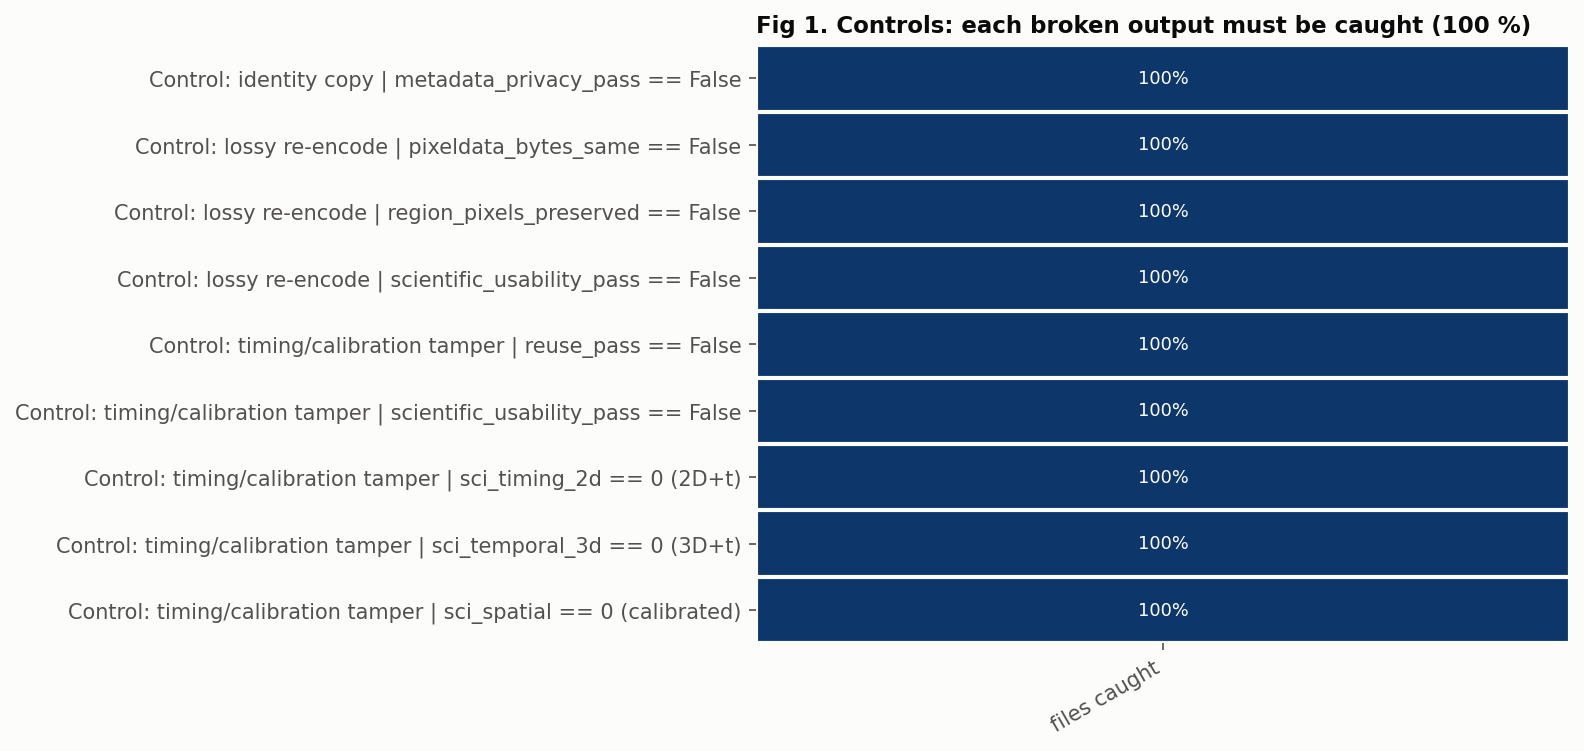

In [6]:
F.controls(cfg, R)

### E1: are the identifiers gone?

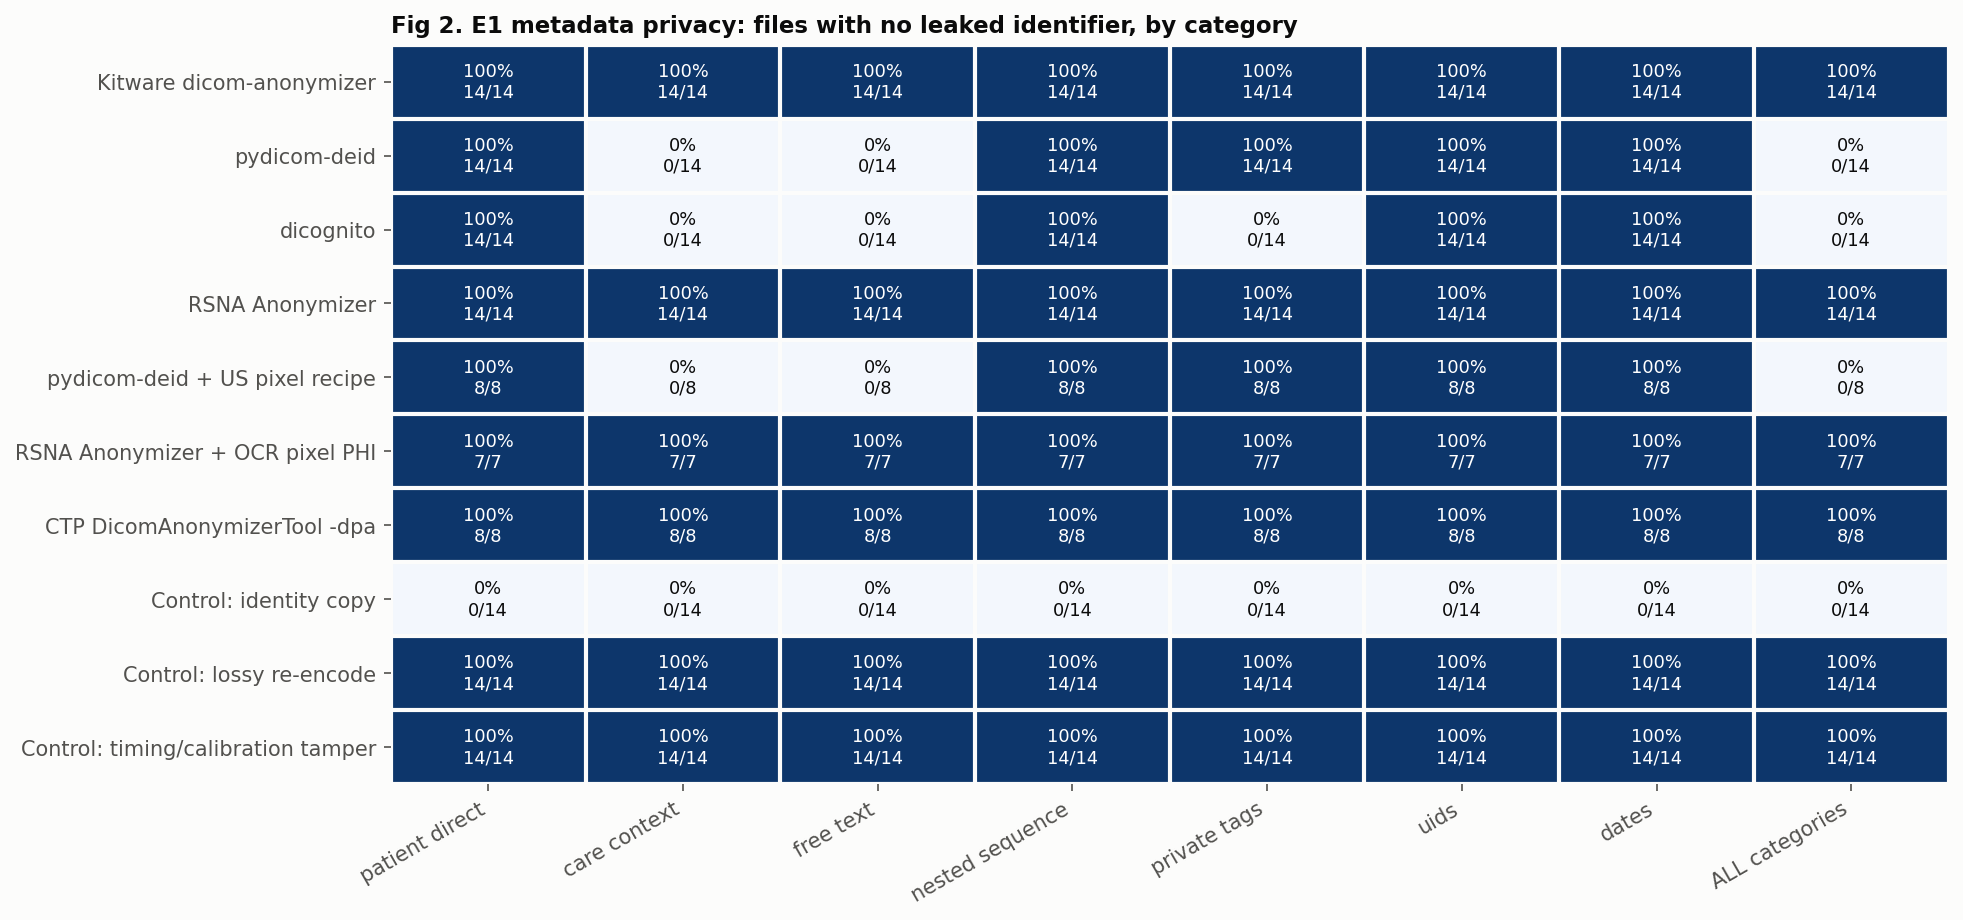

In [7]:
F.privacy(cfg, R)

### E2 + E4: is the cine still usable?

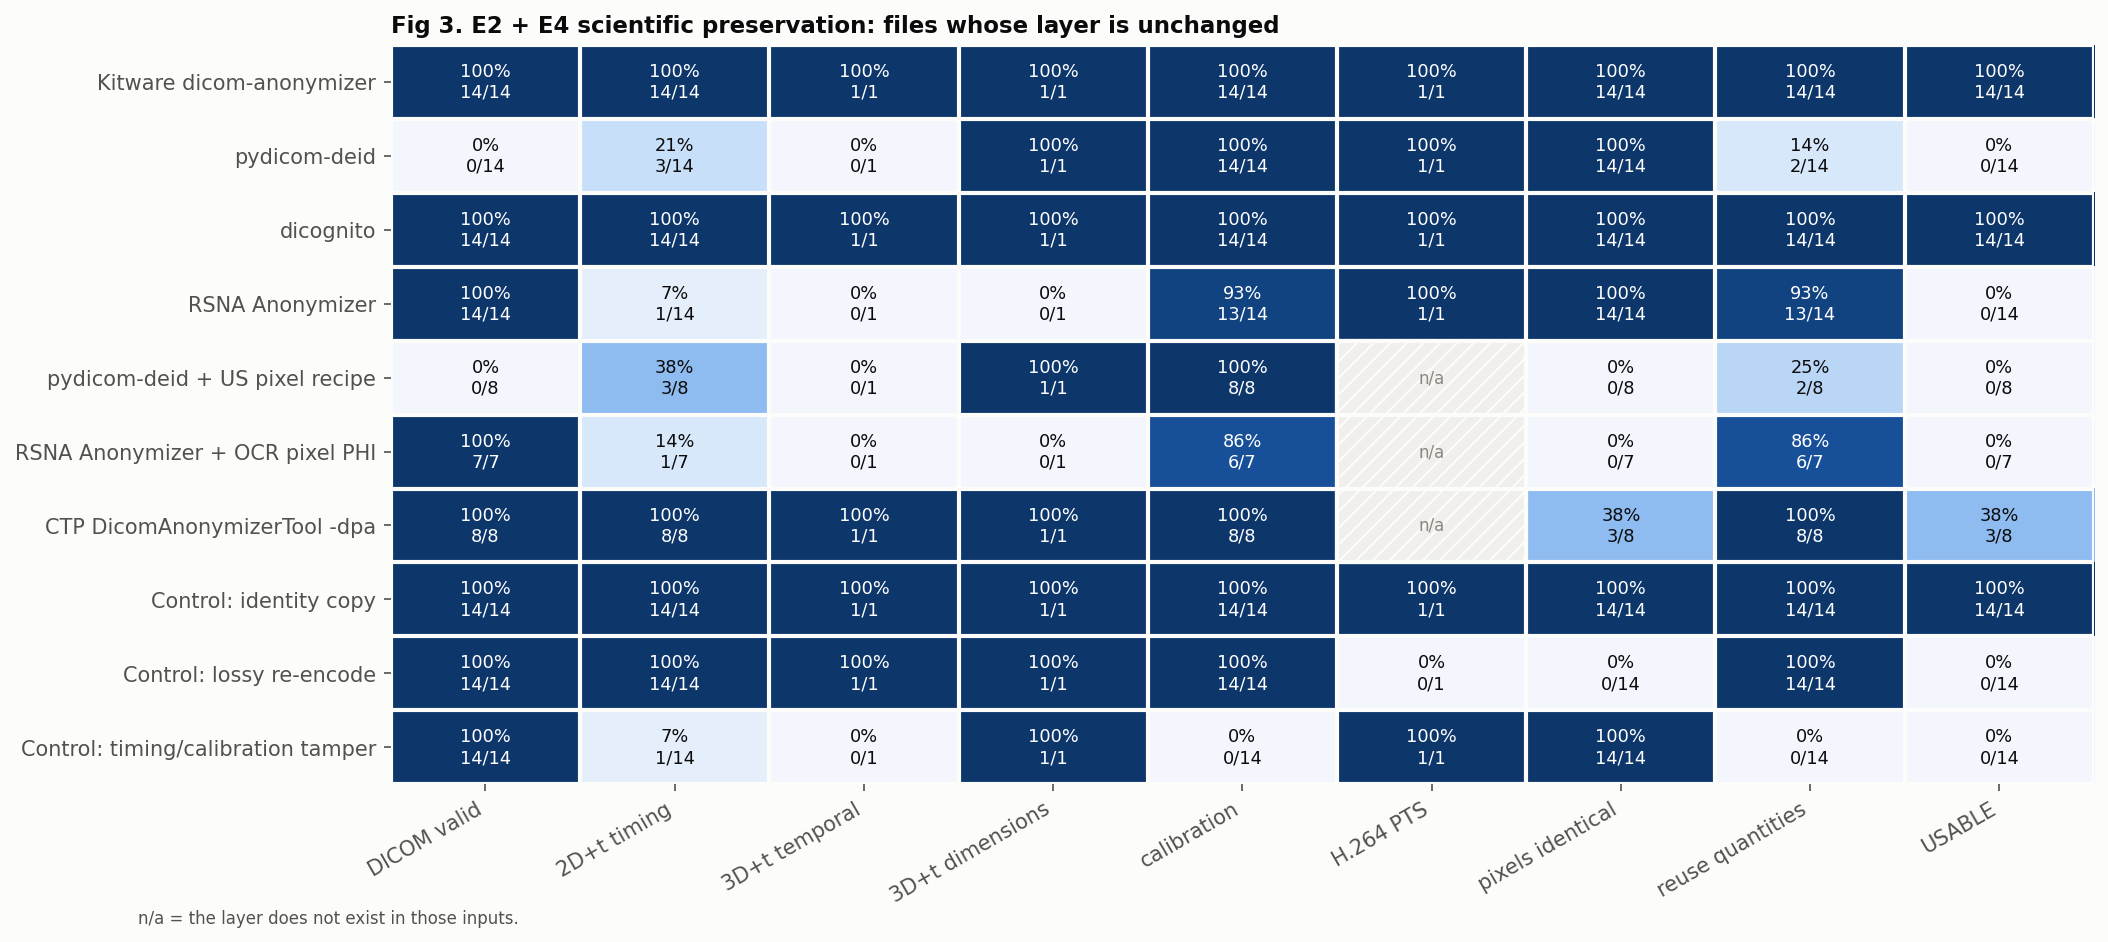

In [8]:
F.preservation(cfg, R)

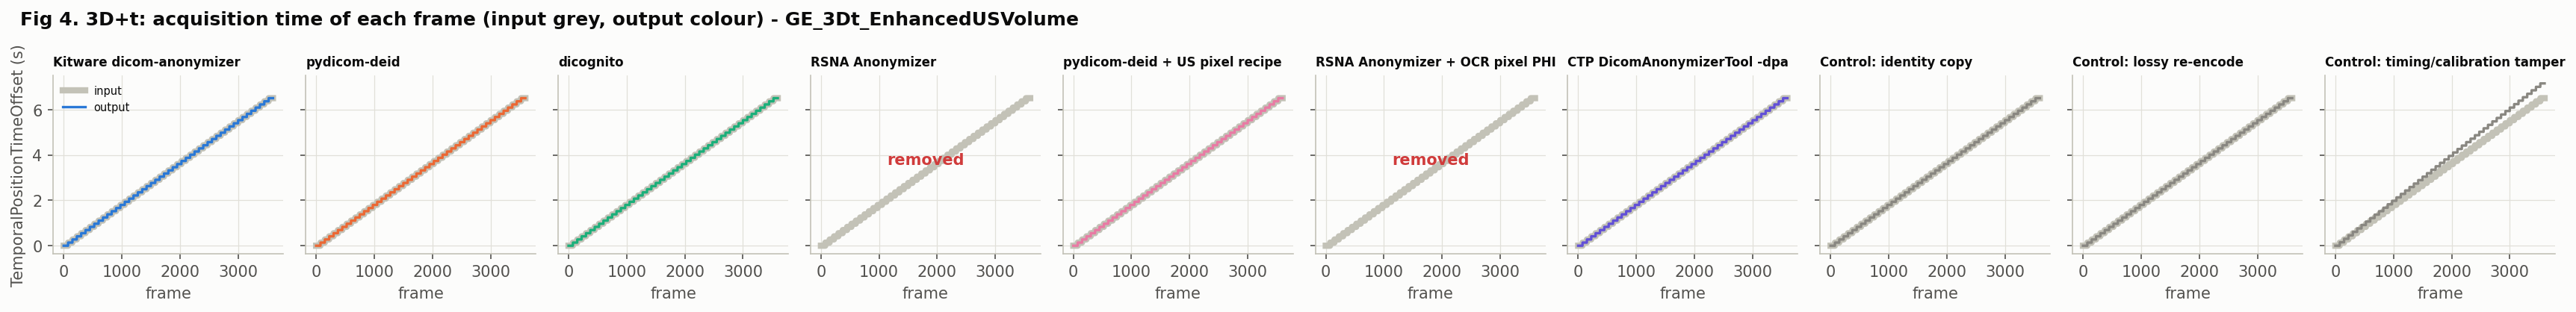

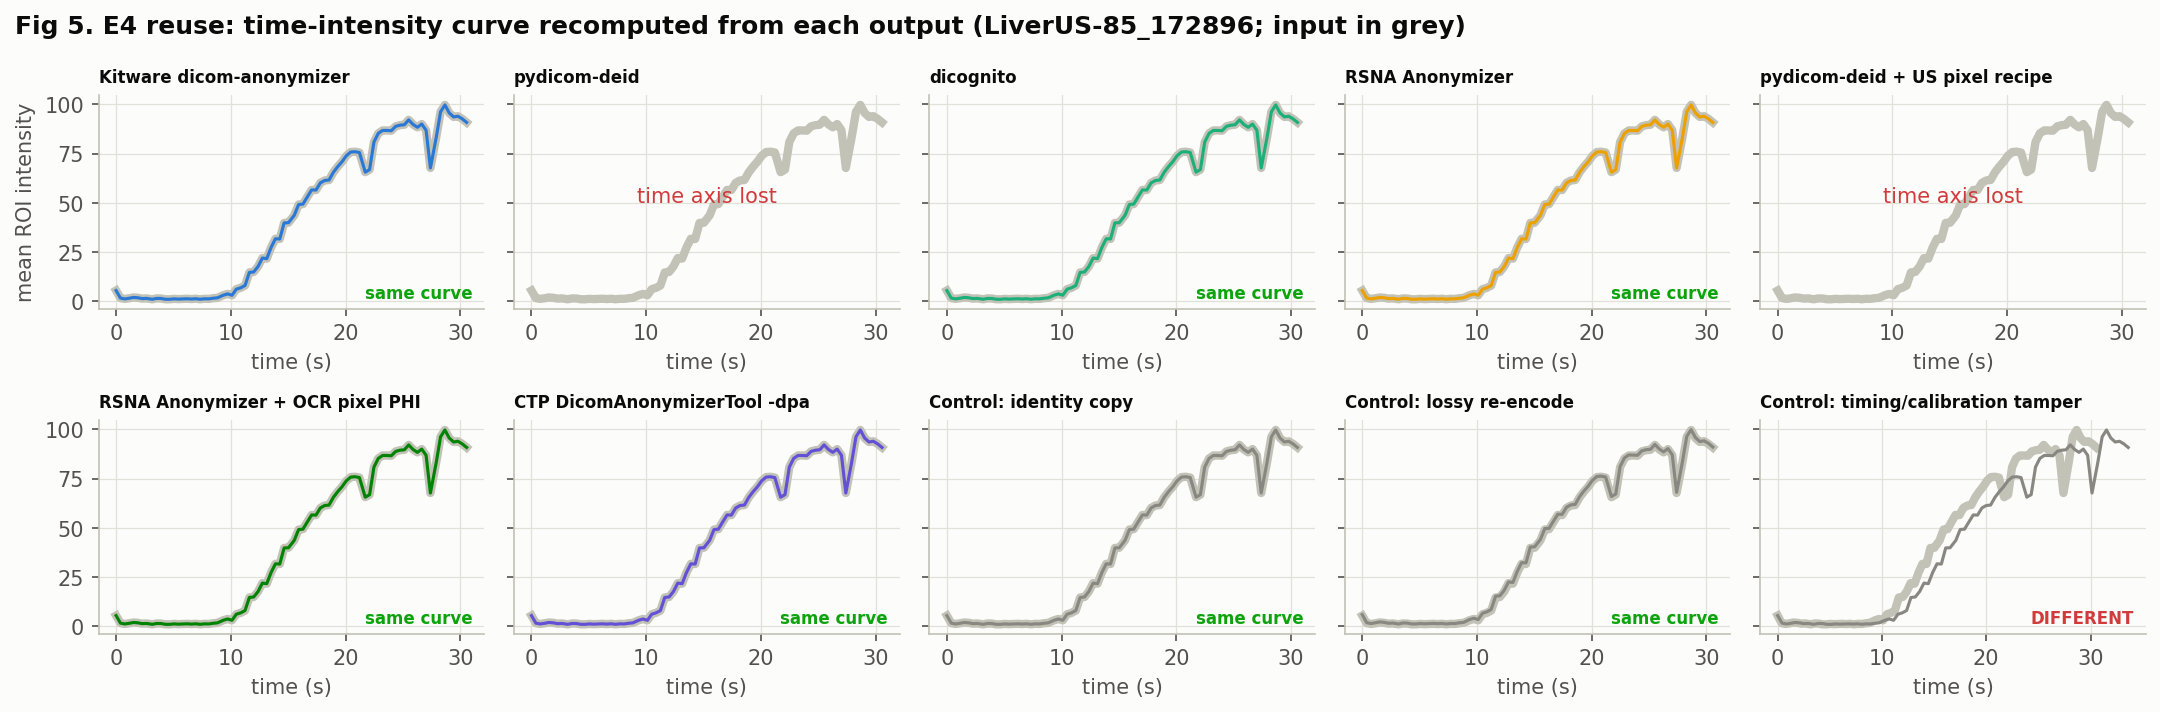

In [9]:
F.temporal_3d(cfg, D, R)
F.reuse_tic(cfg, D, R)

### What the tools do to the images
The same frame of real cines, before and after each tool. "Identical" means not a single pixel changed.

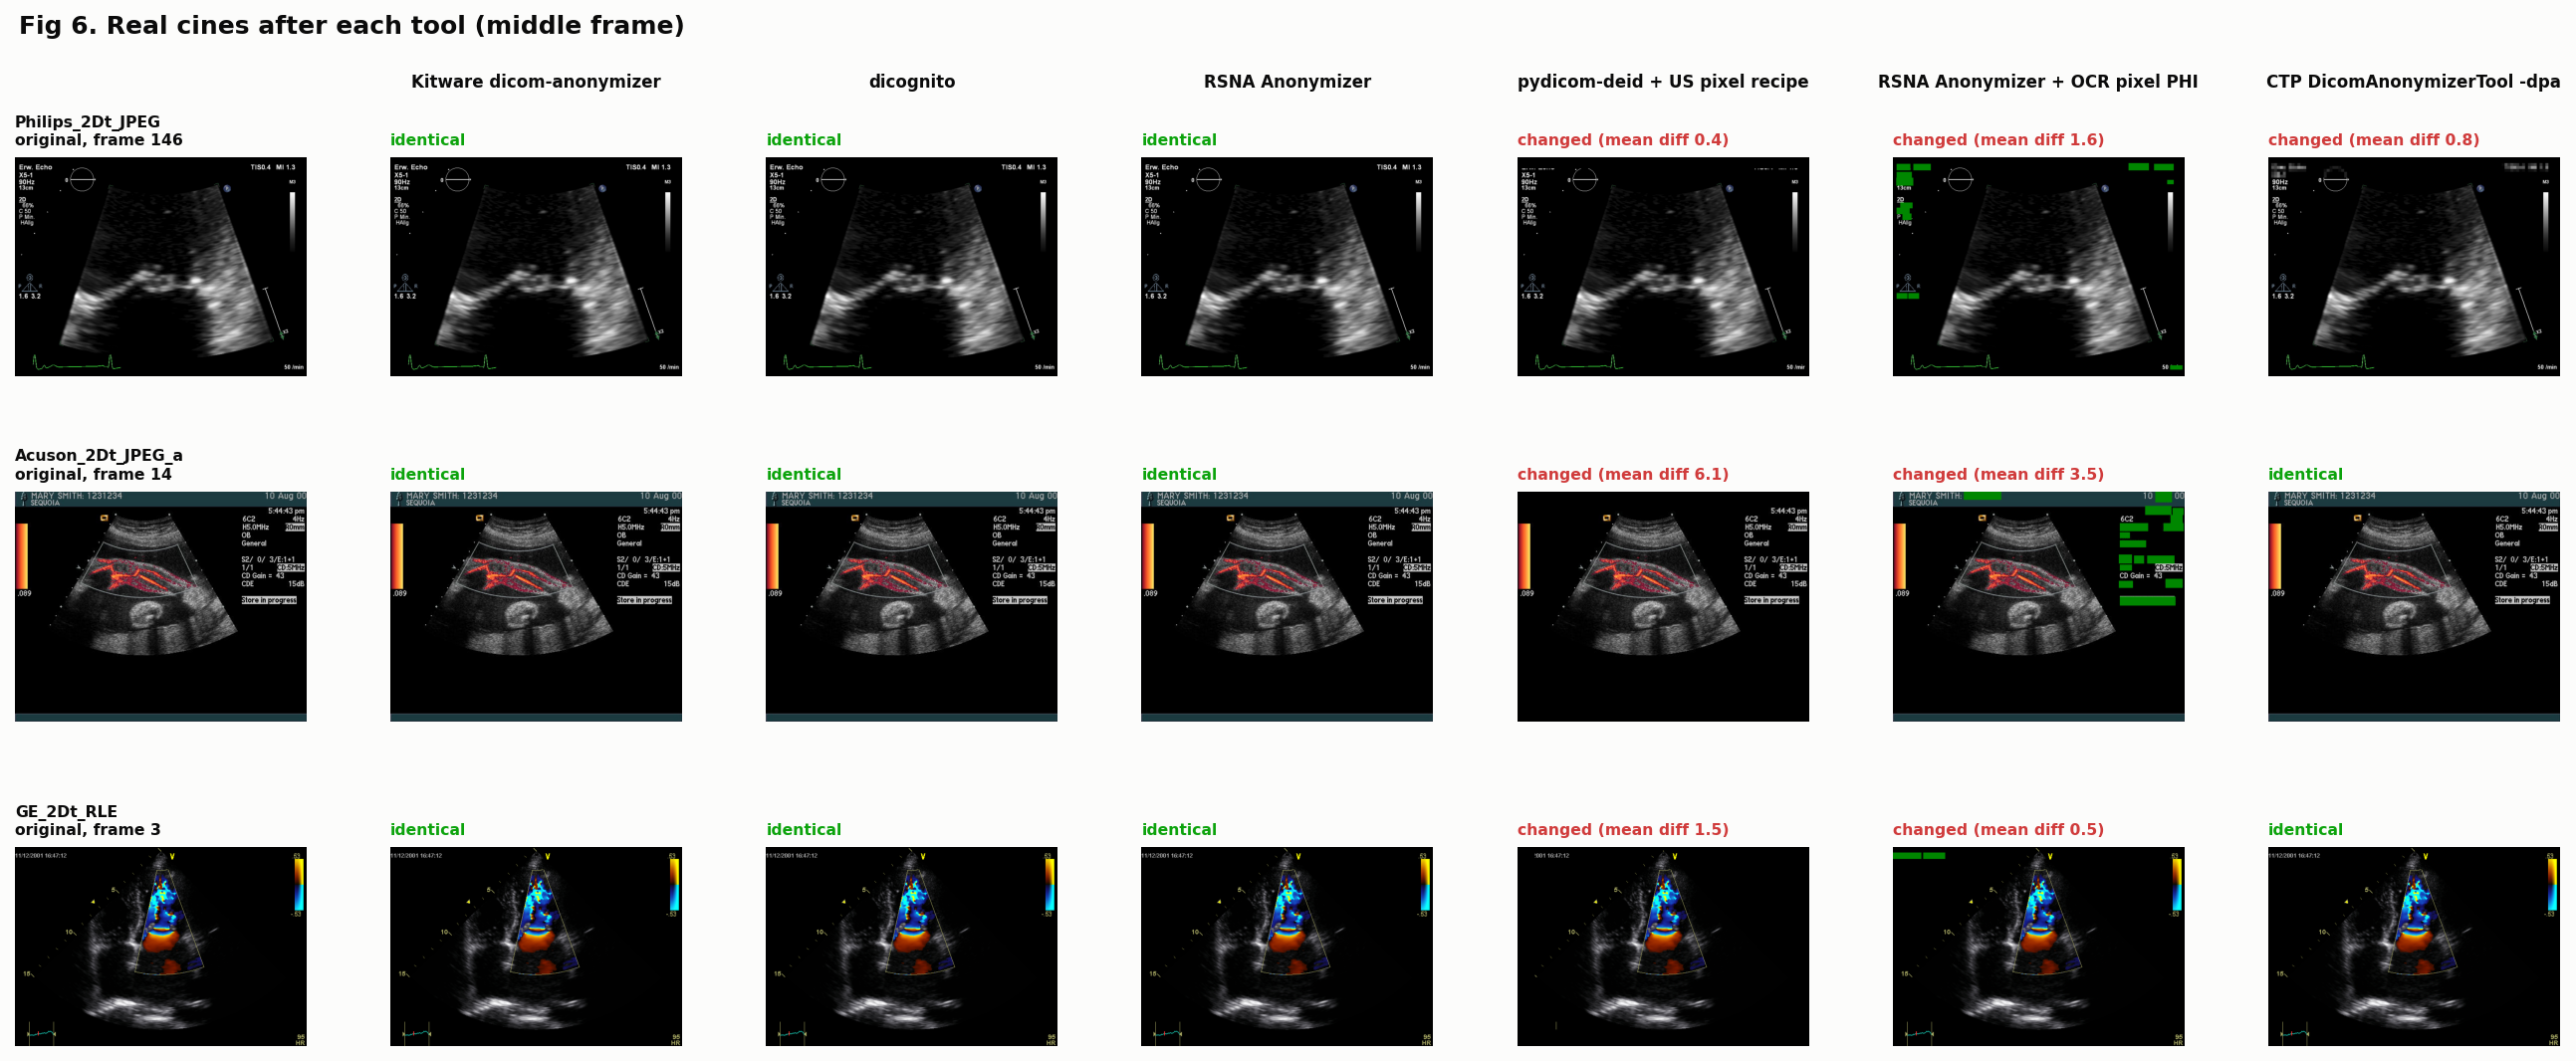

In [10]:
F.real_images(cfg, D, R)

### E3: burned-in text

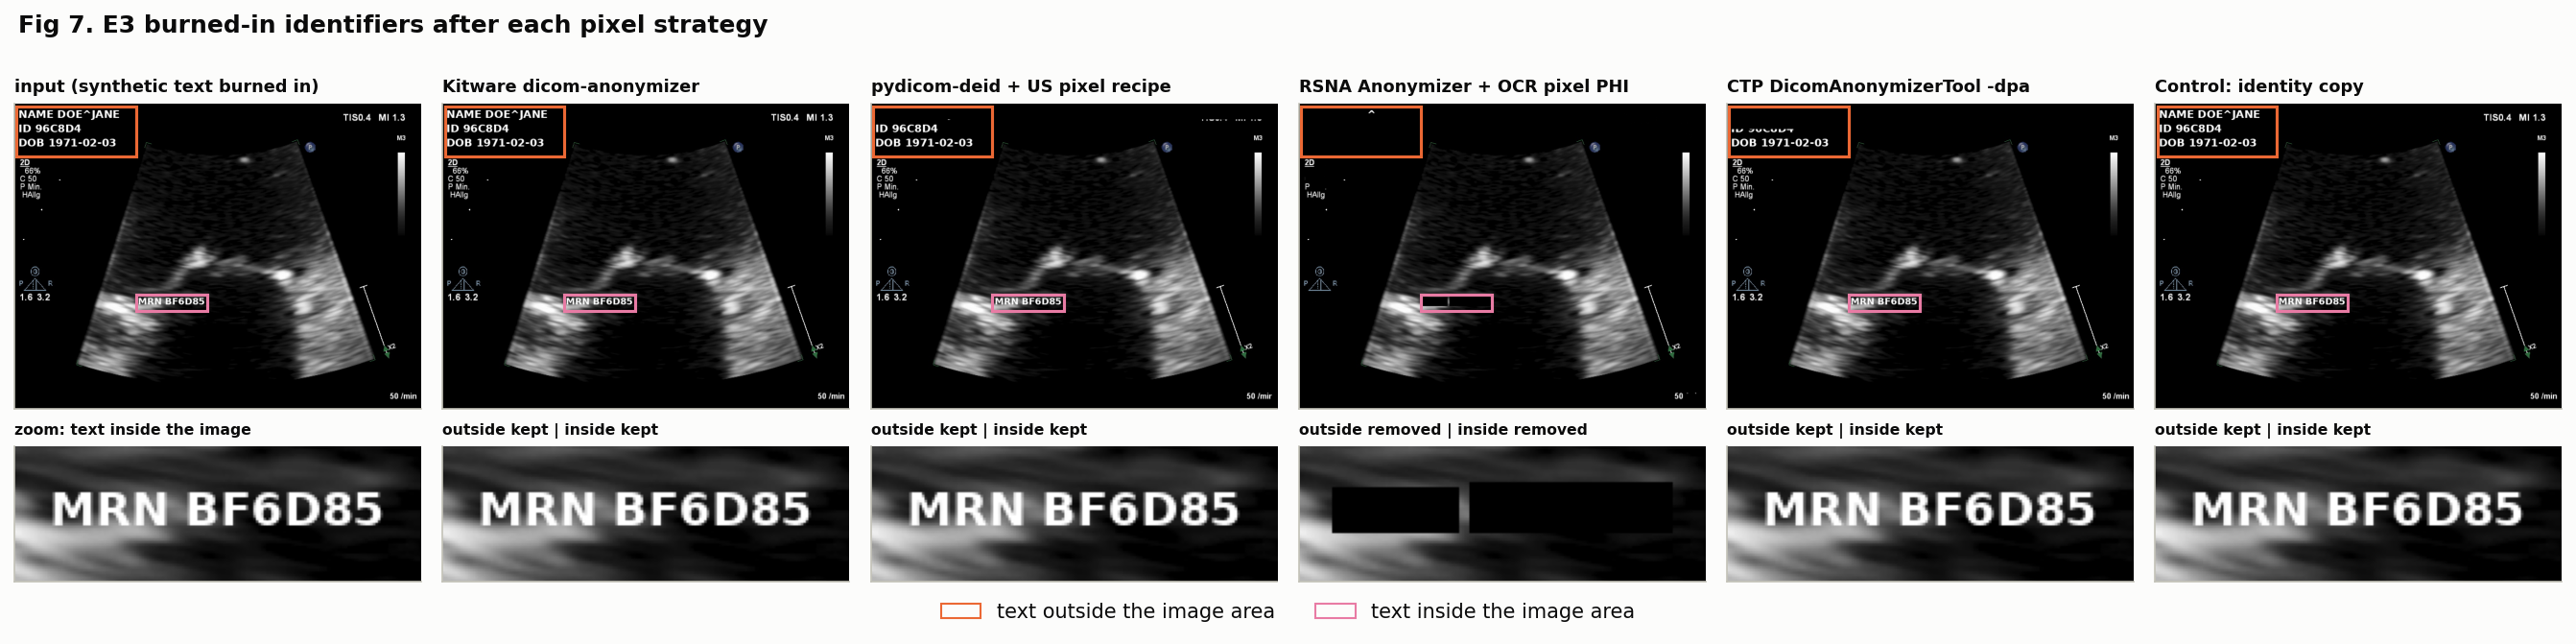

In [11]:
F.burned_in(cfg, D, R)

## 4. Summary

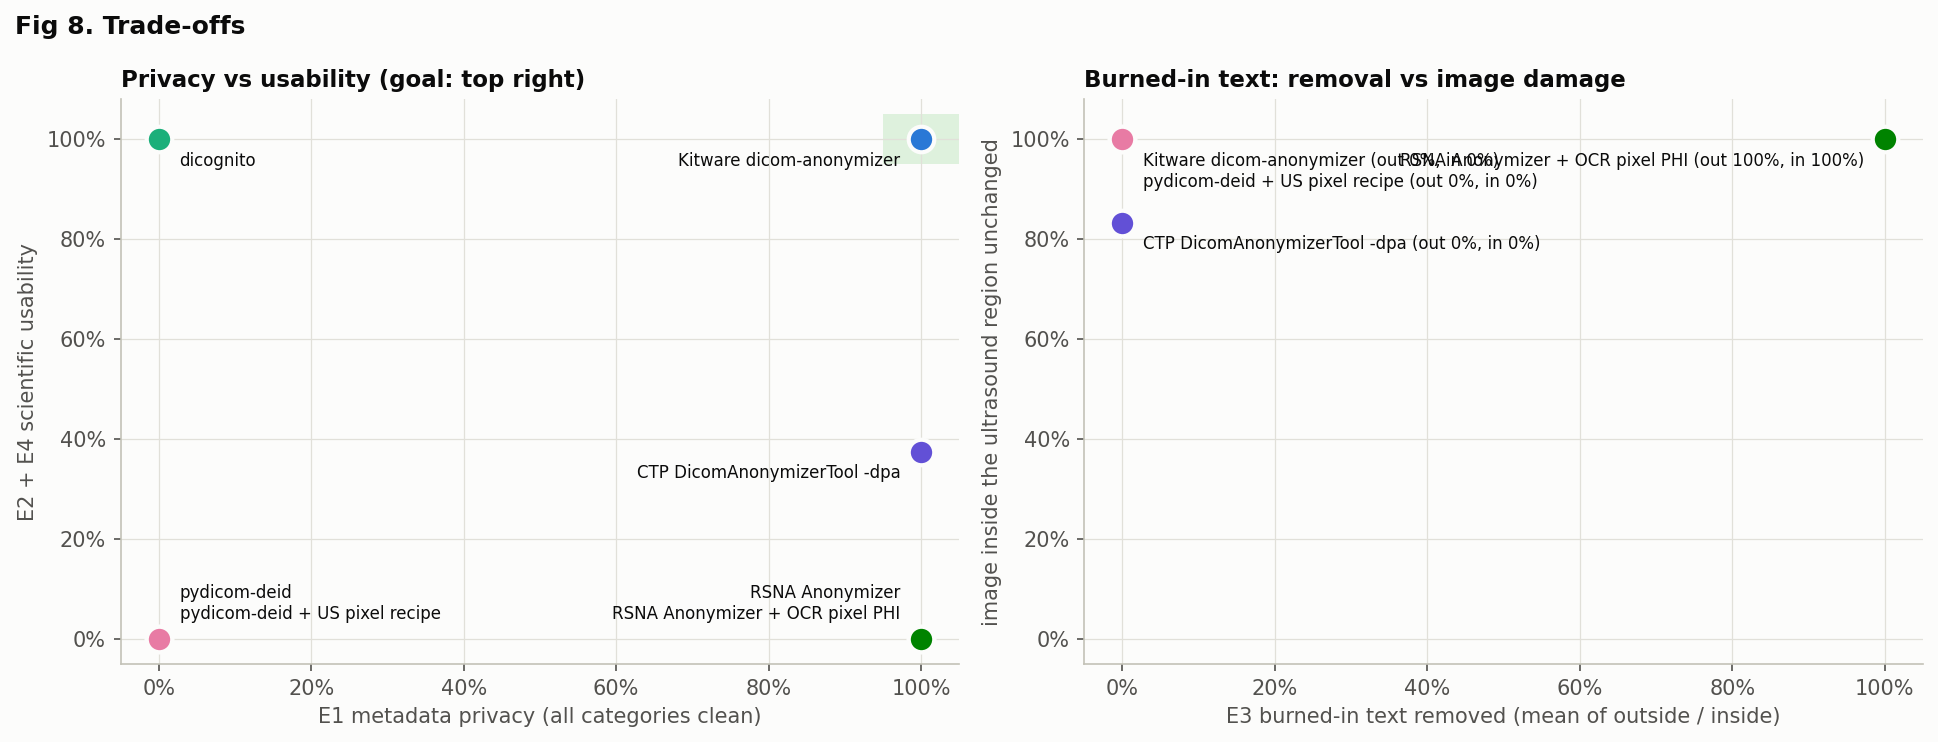

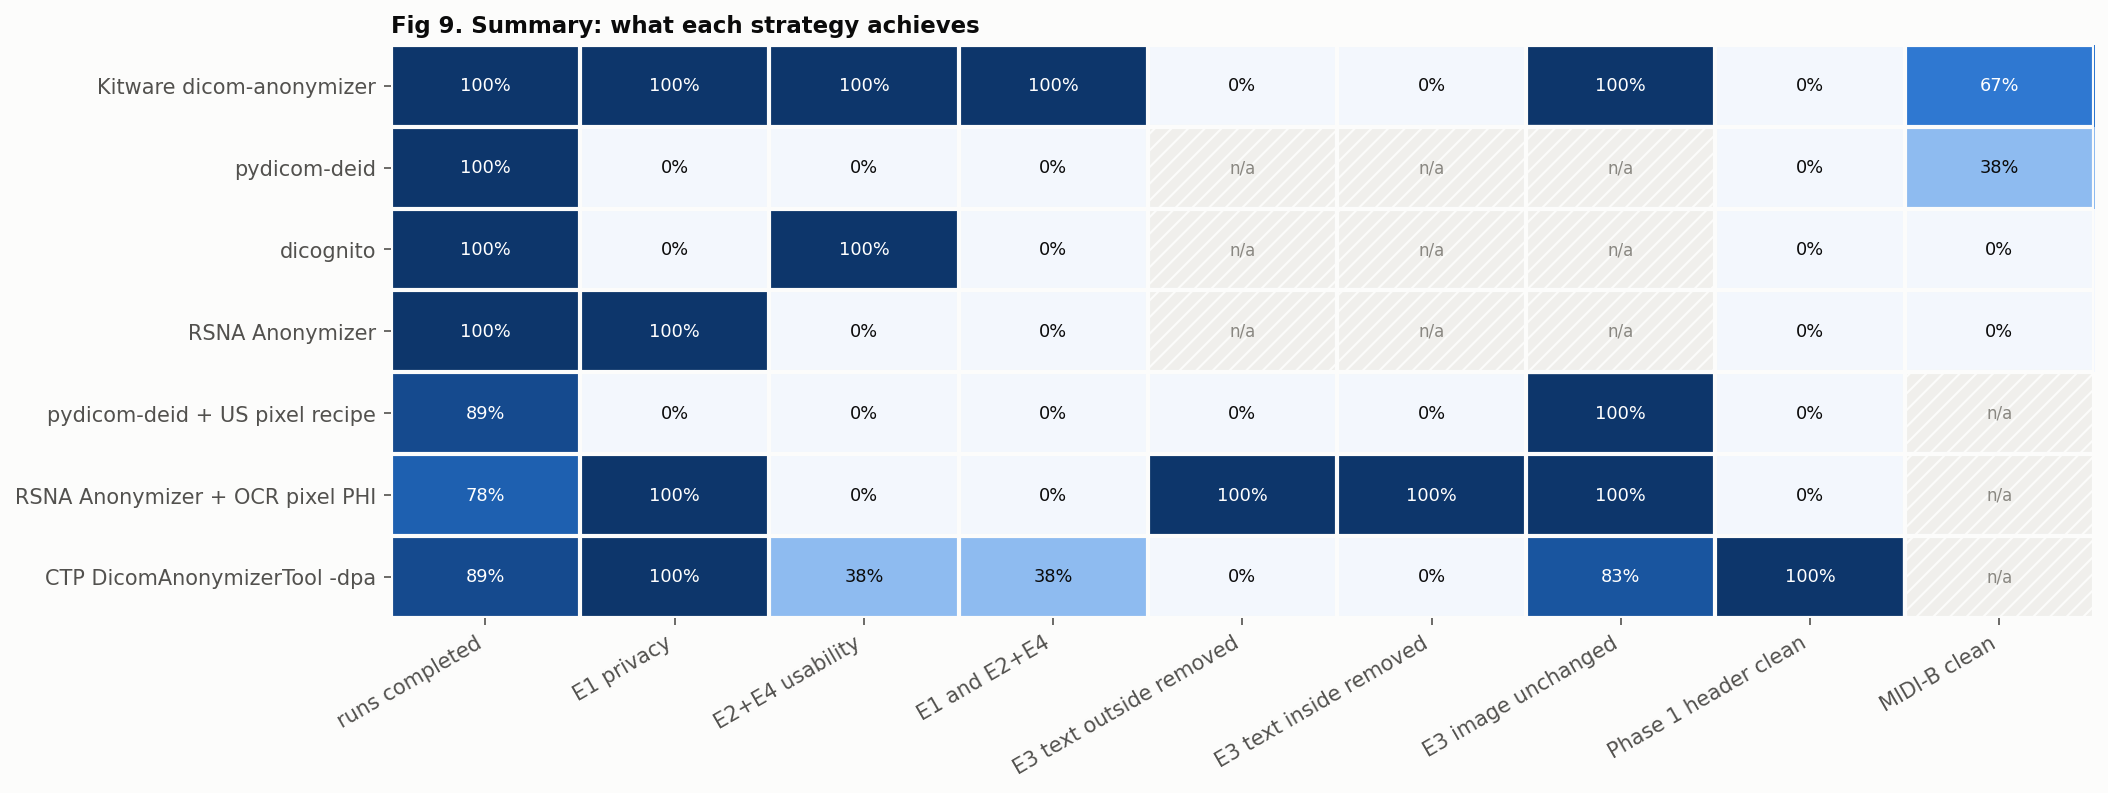

In [12]:
F.tradeoffs(cfg, R)
F.decision_matrix(cfg, R)

In [13]:
cases = D["cases"]
answer = build_answer(R["synthesis"], R["results"], n_files=cases.case_id.nunique(), kinds=cases.kind.value_counts().to_dict(),
                      n_sources=cases.source.nunique(), n_canaries=D["n_canaries"], n_pixel_cases=len(D["pixel_cases"]),
                      n_midi=len(D["midi_inv"]), n_phase1=len(D["p1_cases"]), controls_ok=R["controls_ok"], mode=cfg.mode)
(cfg.results / "answer.md").write_text(answer, encoding="utf-8")
display(Markdown(answer))

**Evidence base (full mode).** 14 temporal ultrasound objects (13 x 2D+t, 1 x 3D+t) from 3 source(s), each seeded with 27 canary identifiers in 7 PHI categories; 12 burned-in text challenges; 1 Phase 1 file(s); 24 MIDI-B synthetic-PHI file(s). Validators were shown able to fail: all control checks were caught.

**Yes, for header (metadata) PHI, with the right tool and profile.** Kitware dicom-anonymizer removed every canary in every category from all temporal files and left timing, 3D+t organisation, calibration, the PixelData bitstream and the reuse quantities unchanged.

- **pydicom-deid** left identifiers in: care context, free text (privacy 0%); altered: 2D+t timing, 3D+t temporal organisation, reuse quantities (usability 0%).

- **dicognito** left identifiers in: care context, free text, private tags (privacy 0%); preserved the scientific content (usability 100%).

- **RSNA Anonymizer** altered: 2D+t timing, 3D+t temporal organisation, 3D+t dimensions, calibration, reuse quantities (usability 0%).

**Burned-in PHI is a separate problem.** Metadata de-identification does not touch the pixels (Kitware, header text removed: 0%).

- **pydicom-deid + US pixel recipe**: header text removed 0%, text inside the imaging region removed 0%, anatomy preserved 100%; on the temporal objects the bitstream stayed identical in 0% of files, usability 0%.

- **RSNA Anonymizer + OCR pixel PHI**: header text removed 100%, text inside the imaging region removed 100%, anatomy preserved 100%; on the temporal objects the bitstream stayed identical in 0% of files, usability 0%.

- **CTP DicomAnonymizerTool -dpa**: header text removed 0%, text inside the imaging region removed 0%, anatomy preserved 83%; on the temporal objects the bitstream stayed identical in 38% of files, usability 38%.

**Conclusion.** De-identification *can* remove identifiable header information without altering what is needed to reuse a temporal ultrasound DICOM, but this is a property of the specific tool, version and profile, and it must be verified per exported file. Removing burned-in PHI is a different trade-off: region-based blanking cannot see text inside the imaging sector, and pixel cleaning re-encodes the cine.

**Limitations.** Identifiers are synthetic and planted in known places; real exports may hide PHI elsewhere. The MIDI-B score uses an answer key derived from the files, not TCIA's official key. The H.264 file is a re-encoded copy, not a vendor export. Burned-in text uses one font. Sample sizes are small.

All tables are in `results/tables/`, figures in `results/figures/`, exact tool versions in `results/environment.json`.

In [14]:
#@title Save results { display-mode: "form" }
from datetime import datetime
if IN_COLAB:
    if SAVE_TO_DRIVE:
        dest = Path("/content/drive/MyDrive/phase2_results") / f"{cfg.mode}_{datetime.now():%Y%m%d_%H%M}"
        shutil.copytree(cfg.results, dest, ignore=shutil.ignore_patterns("work"))
        print("Saved to your Drive:", dest)
    else:
        from google.colab import files
        files.download(shutil.make_archive("/content/phase2_results", "zip", cfg.results))
else:
    print("Results in:", cfg.results)

Saved to your Drive: /content/drive/MyDrive/phase2_results/full_20261106_0505
